# ESMFold2 — Positive net charge in isolated cryo-EM chains


## 1. Data source/acquisition

Use the supplied 150 target sequences and 50 matched triplets. Their identifiers, sequence hashes and matching assignments fix the analysis cohort. Reacquire target structures and run the public RCSB sequence search against experimental protein entities released strictly before 2021-09-30. Among the first 100 hits ranked by sequence-search score, choose the highest bitscore; identity, query coverage and entity identifier break ties. The E-value ceiling is 1. Search responses and structure bytes are fingerprinted for repeatable reuse. These database endpoints are identifier/date constrained; their current response bytes are recorded.

The manifest's control values and template assignments are not used. RCSB documents the search API at https://search.rcsb.org/index.html .


In [1]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from collections import Counter,defaultdict
import os,json,hashlib,urllib.request,subprocess,tarfile,io,time,socket,math,re
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display,Image
os.environ['OMP_NUM_THREADS']='2';os.environ['MKL_NUM_THREADS']='2';os.environ['OPENBLAS_NUM_THREADS']='2'
ROOT=Path(os.environ.get('ESMFOLD_CHARGE_ROOT',str(Path.cwd()/'calculations/charge'))).resolve();ROOT.mkdir(parents=True,exist_ok=True)
RAW=Path(os.environ.get('ESMFOLD_CHARGE_SOURCE_CACHE',str(ROOT/'source_data')));RAW.mkdir(parents=True,exist_ok=True)
def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def acquire(url,path,expected=None):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True);receipt=path.with_suffix(path.suffix+'.source.json')
    if path.is_file() and receipt.is_file():
        known=json.loads(receipt.read_text())
        if sha256_file(path)!=known['sha256']:raise ValueError('Cached source bytes changed: '+str(path))
        if expected and known['sha256']!=expected:raise ValueError('Source fingerprint differs')
        return known
    temporary=path.with_suffix(path.suffix+'.partial')
    request=urllib.request.Request(url,headers={'User-Agent':'SPECTRA-protein-analysis/1.0'})
    for attempt in range(8):
        try:
            response=urllib.request.urlopen(request,timeout=180);break
        except Exception:
            if attempt==7:raise
            time.sleep(min(2**attempt,45))
    with response,temporary.open('wb') as stream:
        headers={key:response.headers.get(key) for key in ['ETag','Last-Modified','Content-Length']}
        while True:
            block=response.read(1024*1024)
            if not block:break
            stream.write(block)
    digest=sha256_file(temporary)
    if expected and digest!=expected:raise ValueError('Downloaded source fingerprint differs')
    temporary.replace(path)
    record={'url':url,'sha256':digest,'bytes':path.stat().st_size,'headers':headers}
    receipt.write_text(json.dumps(record,indent=2));return record
manifest_path=Path.cwd()/'inputs/em_charge_manifest_final.csv'
if sha256_file(manifest_path)!='94bceb56455113436d2884ca1e30316f0066a49a2aa1cc3a2fc3ef481c3338f1':raise ValueError('Charge-cohort manifest fingerprint differs')
manifest=pd.read_csv(manifest_path)
if manifest.candidate_id.duplicated().any():raise ValueError('Duplicate target IDs')
for row in manifest.itertuples():
    if hashlib.sha256(row.sequence.encode()).hexdigest()!=row.sequence_sha256:raise ValueError('Sequence fingerprint differs: '+row.candidate_id)
print('Fixed target cohort:',len(manifest),'protein chains and',manifest.charge_set_id.nunique(),'matched sets')

SEARCH=ROOT/'sequence_search';SEARCH.mkdir(exist_ok=True)
def request_search(sequence):
    payload={'query':{'type':'group','logical_operator':'and','nodes':[
        {'type':'terminal','service':'sequence','parameters':{'evalue_cutoff':1,'identity_cutoff':0,'target':'pdb_protein_sequence','value':sequence}},
        {'type':'terminal','service':'text','parameters':{'attribute':'rcsb_accession_info.initial_release_date','operator':'less','value':'2021-09-30'}}]},
        'return_type':'polymer_entity','request_options':{'paginate':{'start':0,'rows':100},'results_verbosity':'verbose','scoring_strategy':'sequence','sort':[{'sort_by':'score','direction':'desc'}]}}
    encoded=json.dumps(payload,sort_keys=True).encode();key=hashlib.sha256(encoded).hexdigest()
    path=SEARCH/(key+'.json');receipt=SEARCH/(key+'.source.json')
    if path.exists() and receipt.exists():
        saved=json.loads(receipt.read_text())
        if saved['request_sha256']!=key or saved['sha256']!=sha256_file(path):raise ValueError('Sequence-search cache does not match its request or response hash')
        return json.loads(path.read_text()),saved
    request=urllib.request.Request('https://search.rcsb.org/rcsbsearch/v2/query',data=encoded,headers={'Content-Type':'application/json','User-Agent':'SPECTRA-protein-analysis/1.0'})
    for attempt in range(8):
        try:
            with urllib.request.urlopen(request,timeout=180) as response:
                body=response.read();data=json.loads(body) if body else {'result_set':[],'total_count':0}
            break
        except Exception as error:
            if isinstance(error,urllib.error.HTTPError) and error.code in [400,401,403,404]:raise
            if attempt==7:raise
            time.sleep(min(2**attempt,45))
    path.write_text(json.dumps(data,indent=2))
    record={'url':request.full_url,'request':payload,'request_sha256':key,'sha256':sha256_file(path),'retrieved_utc':time.strftime('%Y-%m-%dT%H:%M:%SZ',time.gmtime())}
    receipt.write_text(json.dumps(record,indent=2));time.sleep(.25)
    return data,record
def choose_search_hit(response):
    hits=[]
    for hit in response.get('result_set',[]):
        for service in hit.get('services',[]):
            if service.get('service_type')!='sequence':continue
            for node in service.get('nodes',[]):
                for match in node.get('match_context',[]):
                    qcov=(match['query_end']-match['query_beg']+1)/match['query_length']
                    hits.append({'template_entity_id':hit['identifier'],'template_sequence_identity':float(match['sequence_identity']),
                        'template_query_coverage':qcov,'template_subject_coverage':(match['subject_end']-match['subject_beg']+1)/match['subject_length'],
                        'template_alignment_length':int(match['alignment_length']),'template_evalue':float(match['evalue']),
                        'template_bitscore':float(match['bitscore']),'query_alignment':match['query_aligned_seq'],'template_alignment':match['subject_aligned_seq']})
    if not hits:return None
    return sorted(hits,key=lambda hit:(-hit['template_bitscore'],-hit['template_sequence_identity'],-hit['template_query_coverage'],hit['template_entity_id']))[0]


Fixed target cohort: 150 protein chains and 50 matched sets


In [2]:
def fetch_cif(entry):
    entry=str(entry).upper();path=RAW/(entry+'.cif.gz')
    return entry,acquire('https://files.rcsb.org/download/'+entry+'.cif.gz',path)
search_hits={};search_sources={}
for number,row in enumerate(manifest.itertuples(),1):
    response,record=request_search(row.sequence)
    search_hits[row.candidate_id]=choose_search_hit(response);search_sources[row.candidate_id]=record
    if number%25==0:print('Public sequence searches:',number,'/',len(manifest),flush=True)
entries=sorted(set(manifest.pdb_id)|{hit['template_entity_id'].split('_')[0] for hit in search_hits.values() if hit is not None})
with ThreadPoolExecutor(max_workers=2) as pool:structure_sources=dict(pool.map(fetch_cif,entries))
display(pd.DataFrame([{'entry':entry,**item} for entry,item in structure_sources.items()])[['entry','url','bytes','sha256']])
print('Searches:',len(search_sources),'reference abstentions:',sum(hit is None for hit in search_hits.values()))


Public sequence searches: 25 / 150


Public sequence searches: 50 / 150


Public sequence searches: 75 / 150


Public sequence searches: 100 / 150


Public sequence searches: 125 / 150


Public sequence searches: 150 / 150


,entry,url,bytes,sha256
0,1AR1,https://files.rcsb.org/download/1AR1.cif.gz,226589,8d3e36e747e2b0f06b68445cd7d3863be20f5da8c6aeb0...
1,1CP2,https://files.rcsb.org/download/1CP2.cif.gz,118643,ed3a20f7acd03288c771c99f6841c7619d94d5a6ca130a...
2,1FFT,https://files.rcsb.org/download/1FFT.cif.gz,381677,129e8b064e4d9e89a9e02434f314a2ce34038779e7d951...
3,1I1R,https://files.rcsb.org/download/1I1R.cif.gz,118438,aa9ca4689dfe081e6397fd5b1f981bdb80a4b9c7d77ae1...
4,1IZN,https://files.rcsb.org/download/1IZN.cif.gz,240633,e87fffb980d96f13bdeedcb133f01773aa88c7506d6b02...
...,...,...,...,...
223,9SW6,https://files.rcsb.org/download/9SW6.cif.gz,2231575,45289b0db224997d5d86c411ce0dbbd0d160cc7c95de5e...
224,9T17,https://files.rcsb.org/download/9T17.cif.gz,251662,4847a89879ddba51b92d6e3e6367adf4f9f8522191a865...
225,9UIQ,https://files.rcsb.org/download/9UIQ.cif.gz,464315,ae038990630e9e7425942de87c09f2b66f09ffa9e81548...
226,9VHE,https://files.rcsb.org/download/9VHE.cif.gz,500864,4904eb4be781218d17b589fe234d47364f1cf2249d083c...


Searches: 150 reference abstentions: 26


## 2. Data processing

Read experimental method, resolution and entity copy count from the target mmCIF. Verify the mmCIF canonical entity sequence against the fixed query sequence. Extract the specified target chain; for each searched reference entity, choose its chain with the most resolved C-alpha residues, with a lexical chain-ID tie break. No model scores enter these choices. Sequence identity and coverage come from the actual search alignment. Recalculate length, entropy, repeat burden, composition and target C-alpha coverage. A missing usable reference chain is an abstention with reference score zero.


In [3]:
import gemmi
from Bio.SeqUtils import seq3
CHAIN_DIR=ROOT/'experimental_chains';CHAIN_DIR.mkdir(exist_ok=True)
def cif_values(block,name):return [gemmi.cif.as_string(value) for value in block.find_values(name)]
def numeric_values(values):
    result=[]
    for value in values:
        try:result.append(float(value))
        except (ValueError,TypeError):pass
    return [value for value in result if np.isfinite(value)]
def entity_metadata(entry,entity):
    block=gemmi.cif.read(str(RAW/(entry+'.cif.gz'))).sole_block()
    poly_ids=cif_values(block,'_entity_poly.entity_id');sequences=cif_values(block,'_entity_poly.pdbx_seq_one_letter_code_can')
    if str(entity) not in poly_ids:raise ValueError('Entity absent in downloaded mmCIF: '+entry+'_'+str(entity))
    sequence=''.join(sequences[poly_ids.index(str(entity))].split()).upper()
    copies=sum(value==str(entity) for value in cif_values(block,'_struct_asym.entity_id'))
    method='; '.join(cif_values(block,'_exptl.method'))
    resolutions=numeric_values(cif_values(block,'_em_3d_reconstruction.resolution')) if 'ELECTRON MICROSCOPY' in method else numeric_values(cif_values(block,'_refine.ls_d_res_high'))
    if not resolutions or copies<1:raise ValueError('Missing experimental metadata for '+entry)
    return {'experimental_method':method,'resolution_angstrom':min(resolutions),'chain_multiplicity':copies,'entity_sequence':sequence}
def ca_chains(entry,entity=None):
    block=gemmi.cif.read(str(RAW/(entry+'.cif.gz'))).sole_block()
    if entity is None:allowed=None
    else:
        allowed={chain for chain,e in zip(cif_values(block,'_atom_site.auth_asym_id'),cif_values(block,'_atom_site.label_entity_id')) if e==str(entity)}
    structure=gemmi.make_structure_from_block(block);structure.merge_chain_parts();out={}
    for chain in structure[0]:
        if allowed is not None and chain.name not in allowed:continue
        sequence=[];coordinates=[]
        for residue in chain:
            aa=gemmi.find_tabulated_residue(residue.name).one_letter_code.upper()
            if aa not in 'ACDEFGHIKLMNPQRSTVWY':continue
            atoms=[atom for atom in residue if atom.name=='CA' and atom.altloc in ['\x00','A']]
            if not atoms:continue
            atom=atoms[0];sequence.append(aa);coordinates.append([atom.pos.x,atom.pos.y,atom.pos.z])
        if sequence:out[chain.name]=(''.join(sequence),np.asarray(coordinates,dtype=float))
    return out
def write_ca_pdb(sequence,coordinates,path):
    lines=[]
    for i,(aa,xyz) in enumerate(zip(sequence,coordinates),1):
        x,y,z=xyz;lines.append(f'ATOM  {i:5d}  CA  {seq3(aa).upper():>3s} A{i:4d}    {x:8.3f}{y:8.3f}{z:8.3f}  1.00 50.00           C')
    Path(path).write_text('\n'.join(lines+['TER','END'])+'\n')
def sequence_features(sequence):
    n=len(sequence);counts=Counter(sequence);p=np.array(list(counts.values()),float)/n
    covered=np.zeros(n,dtype=bool);positions=defaultdict(list)
    for i in range(n-3):positions[sequence[i:i+4]].append(i)
    for starts in positions.values():
        if len(starts)<2:continue
        for start in starts:
            if start-starts[0]>=24 or starts[-1]-start>=24:covered[start:start+4]=True
    return {'sequence_length':n,'normalized_sequence_entropy':float(-(p*np.log(p)).sum()/np.log(20)),
            'distant_repeat4_coverage':float(covered.mean()),'max_residue_fraction':max(counts.values())/n,
            'cysteine_fraction':counts['C']/n,'gly_pro_fraction':(counts['G']+counts['P'])/n,
            'hydrophobic_fraction':sum(counts[aa] for aa in 'AILMFWYV')/n}

rows=[]
for row in manifest.itertuples():
    metadata=entity_metadata(row.pdb_id,row.entity_id)
    if hashlib.sha256(metadata.pop('entity_sequence').encode()).hexdigest()!=row.sequence_sha256:raise ValueError('Downloaded entity sequence differs: '+row.candidate_id)
    targets=ca_chains(row.pdb_id,row.entity_id)
    if str(row.target_chain_extracted) not in targets:raise ValueError('Target chain is absent: '+row.candidate_id)
    target_sequence,target_xyz=targets[str(row.target_chain_extracted)]
    record={key:getattr(row,key) for key in ['candidate_id','pdb_id','entity_id','sequence','sequence_sha256','charge_set_id','cluster','target_chain_extracted']}
    record.update(metadata);record.update(sequence_features(row.sequence))
    record['target_resolved_ca_fraction']=len(target_sequence)/len(row.sequence)
    record['target_chain_path']=str(CHAIN_DIR/(row.candidate_id+'_target.pdb'))
    write_ca_pdb(target_sequence,target_xyz,record['target_chain_path'])
    hit=search_hits[row.candidate_id]
    record.update({'template_entity_id':None,'template_pdb_id':None,'template_chain_extracted':None,'template_chain_path':None,'template_sequence_identity':0.0,'template_query_coverage':0.0,'template_abstained':True})
    if hit is not None:
        record.update(hit);entry,entity=hit['template_entity_id'].split('_');record['template_pdb_id']=entry
        references={chain:value for chain,value in ca_chains(entry,entity).items() if len(value[0])>=3}
        if references:
            chain=sorted(references,key=lambda name:(-len(references[name][0]),name))[0]
            record['template_chain_extracted']=chain;record['template_chain_path']=str(CHAIN_DIR/(row.candidate_id+'_template.pdb'));record['template_abstained']=False
            write_ca_pdb(*references[chain],record['template_chain_path'])
    rows.append(record)
features=pd.DataFrame(rows)
if not features.sequence_length.between(289,336).all():raise ValueError('Length scope differs')
if not features.target_resolved_ca_fraction.ge(.8).all():raise ValueError('A target fails the 80% resolved-residue requirement')
if not features.experimental_method.str.contains('ELECTRON MICROSCOPY').all():raise ValueError('The fixed cohort contains a non-EM target')
features.to_csv(ROOT/'processed_inputs.csv',index=False)
display(features[['candidate_id','sequence_length','experimental_method','resolution_angstrom','chain_multiplicity','template_entity_id','template_sequence_identity','template_query_coverage','target_resolved_ca_fraction']])


,candidate_id,sequence_length,experimental_method,resolution_angstrom,chain_multiplicity,template_entity_id,template_sequence_identity,template_query_coverage,target_resolved_ca_fraction
0,8VD5_1,324,ELECTRON MICROSCOPY,3.20,4,6B0X_1,1.000,1.000000,0.901235
1,9HLZ_67,319,ELECTRON MICROSCOPY,3.20,1,3J6B_20,1.000,1.000000,0.862069
2,9HLZ_32,319,ELECTRON MICROSCOPY,3.20,1,5MRC_65,1.000,0.855799,0.855799
3,8B6H_19,318,ELECTRON MICROSCOPY,2.60,2,NaN,0.000,0.000000,0.921384
4,9E2G_19,297,ELECTRON MICROSCOPY,2.80,1,NaN,0.000,0.000000,0.929293
...,...,...,...,...,...,...,...,...,...
145,9E78_19,306,ELECTRON MICROSCOPY,2.90,1,NaN,0.000,0.000000,0.830065
146,9E78_33,312,ELECTRON MICROSCOPY,2.90,4,NaN,0.000,0.000000,0.910256
147,8ECN_1,312,ELECTRON MICROSCOPY,2.70,9,3JB5_1,0.381,0.977564,0.987179
148,7Z30_3,335,ELECTRON MICROSCOPY,2.90,1,4C2M_7,1.000,1.000000,1.000000


## 3. Axis definition and level construction

Charge is((K+R)−(D+E))/length. Levels are≤−0.0253702, above that through0, and>0. Verify that each matched set contains exactly one chain at each level.


In [4]:
features['net_charge_proxy']=features.sequence.map(lambda sequence:(sequence.count('K')+sequence.count('R')-sequence.count('D')-sequence.count('E'))/len(sequence))
def charge_level(value):
    if value<=-.0253702:return 'negative_control'
    if value<=0:return 'neutral'
    return 'positive_high_risk'
LEVELS=['negative_control','neutral','positive_high_risk']
features['charge_level']=features.net_charge_proxy.map(charge_level)
counts=pd.crosstab(features.charge_set_id,features.charge_level).reindex(columns=LEVELS,fill_value=0)
if not counts.eq(1).all().all() or len(counts)!=50:raise ValueError('Expected50 matched triplets with one chain at each charge level')
display(features[['candidate_id','charge_set_id','net_charge_proxy','charge_level']])
display(features.groupby('charge_level').agg(n=('candidate_id','size'),charge_min=('net_charge_proxy','min'),charge_median=('net_charge_proxy','median'),charge_max=('net_charge_proxy','max')))


,candidate_id,charge_set_id,net_charge_proxy,charge_level
0,8VD5_1,em_charge_01,-0.030864,negative_control
1,9HLZ_67,em_charge_01,0.000000,neutral
2,9HLZ_32,em_charge_01,0.025078,positive_high_risk
3,8B6H_19,em_charge_02,-0.040881,negative_control
4,9E2G_19,em_charge_02,0.000000,neutral
...,...,...,...,...
145,9E78_19,em_charge_49,-0.006536,neutral
146,9E78_33,em_charge_49,0.025641,positive_high_risk
147,8ECN_1,em_charge_50,-0.035256,negative_control
148,7Z30_3,em_charge_50,-0.023881,neutral


,n,charge_min,charge_median,charge_max
charge_level,,,,
negative_control,50,-0.103896,-0.038690,-0.025806
neutral,50,-0.025316,-0.009318,0.000000
positive_high_risk,50,0.003125,0.025724,0.107843


## 4. Model evaluation

Use the specified Biohub weights through Transformers5.22.2. The two visible converter cells implement the public Hugging Face tensor-layout conversion; an already converted checkpoint may be supplied through ESMFOLD_CHECKPOINT. Predict every sequence with seed0,3 loops,14 diffusion steps and1 sample. A cached prediction is reused only if its input/model/settings receipt and coordinate hash match. US-align calculates target-normalized TM-score for model and template coordinates.


In [5]:
# Hugging Face Transformers converter, Apache-2.0, commit3d87599b23ff5f630de770e08eeed64950e25a9e.
import argparse
import glob
import json
import os
import torch
from huggingface_hub import HfApi, save_torch_state_dict, snapshot_download
from safetensors.torch import load_file
from transformers import EsmcConfig, EsmcTokenizer
esmc__LEGACY_FIELDS = ('vocab_size', 'initializer_range', 'pad_token_id', 'tie_word_embeddings', 'mask_token_id', 'classifier_dropout')
esmc__LEGACY_RENAMES = {'hidden_size': 'd_model', 'num_attention_heads': 'n_heads', 'num_hidden_layers': 'n_layers'}
esmc__LEGACY_DROP_KEYS = {'architectures', 'model_type', 'transformers_version'}
esmc__WEIGHT_KEY_RENAMES = (('embed.', 'embed_tokens.'), ('transformer.blocks.', 'layers.'), ('transformer.norm.', 'norm.'), ('attn.layernorm_qkv.layer_norm_weight', 'input_layernorm.weight'), ('attn.layernorm_qkv.layer_norm_bias', 'input_layernorm.bias'), ('attn.q_ln.', 'self_attn.q_norm.'), ('attn.k_ln.', 'self_attn.k_norm.'), ('attn.out_proj.', 'self_attn.o_proj.'), ('ffn.layer_norm_weight', 'post_attention_layernorm.weight'), ('ffn.layer_norm_bias', 'post_attention_layernorm.bias'), ('ffn.fc2_weight', 'mlp.down_proj.weight'), ('lm_head.0.', 'lm_head.dense.'), ('lm_head.2.', 'lm_head.layer_norm.'), ('lm_head.3.', 'lm_head.decoder.'))
esmc__PACKED_QKV_SUFFIX = 'attn.layernorm_qkv.weight'
esmc__PACKED_GATE_UP_SUFFIX = 'ffn.fc1_weight'
esmc__WEIGHT_KEY_DROP_SUFFIX = '_extra_state'

def esmc__read_json(directory: str) -> dict:
    with open(os.path.join(directory, 'config.json')) as f:
        return json.load(f)

def esmc_build_esmc_config_dict(esmc_dir: str) -> dict:
    old = esmc__read_json(esmc_dir)
    config = {field: old[field] for field in esmc__LEGACY_FIELDS if field in old}
    for port_field, legacy_field in esmc__LEGACY_RENAMES.items():
        config[port_field] = old[legacy_field]
    config['intermediate_size'] = int((8 / 3 * config['hidden_size'] + 255) // 256 * 256)
    if 'dtype' in old:
        config['dtype'] = old['dtype']
    mapped = {*esmc__LEGACY_FIELDS, *esmc__LEGACY_RENAMES.values(), 'dtype'}
    unexpected = set(old) - (mapped | esmc__LEGACY_DROP_KEYS)
    if unexpected:
        raise ValueError(f'unmapped fields in the source ESMC config: {sorted(unexpected)}')
    return config

def esmc_build_config(esmc_dir: str) -> EsmcConfig:
    config = esmc_build_esmc_config_dict(esmc_dir)
    config['architectures'] = ['EsmcForMaskedLM']
    return EsmcConfig.from_dict(config)

def esmc_convert_esmc_state_dict(state_dict: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    converted: dict[str, torch.Tensor] = {}
    for key, tensor in state_dict.items():
        if key.endswith(esmc__WEIGHT_KEY_DROP_SUFFIX):
            continue
        for old, new in esmc__WEIGHT_KEY_RENAMES:
            key = key.replace(old, new)
        if key.endswith(esmc__PACKED_QKV_SUFFIX):
            base = key[:-len(esmc__PACKED_QKV_SUFFIX)]
            q, k, v = (chunk.clone() for chunk in torch.chunk(tensor, 3, dim=0))
            converted.update({base + 'self_attn.q_proj.weight': q, base + 'self_attn.k_proj.weight': k, base + 'self_attn.v_proj.weight': v})
        elif key.endswith(esmc__PACKED_GATE_UP_SUFFIX):
            base = key[:-len(esmc__PACKED_GATE_UP_SUFFIX)]
            gate, up = (chunk.clone() for chunk in torch.chunk(tensor, 2, dim=0))
            converted.update({base + 'mlp.gate_proj.weight': gate, base + 'mlp.up_proj.weight': up})
        else:
            converted[key] = tensor
    return converted

def esmc__load_state_dict(directory: str) -> dict[str, torch.Tensor]:
    shards = sorted(glob.glob(os.path.join(directory, '*.safetensors')))
    if not shards:
        raise FileNotFoundError(f'no *.safetensors weights found in {directory}')
    state_dict: dict[str, torch.Tensor] = {}
    for shard in shards:
        state_dict.update(load_file(shard))
    return state_dict

def esmc_save_tokenizer(output_dir: str) -> None:
    EsmcTokenizer().save_pretrained(output_dir)


In [6]:
# Hugging Face Transformers converter, Apache-2.0, commit3d87599b23ff5f630de770e08eeed64950e25a9e.
import argparse
import glob
import json
import os
import re
import torch
from huggingface_hub import HfApi, save_torch_state_dict, snapshot_download
from safetensors.torch import load_file
from transformers import EsmcTokenizer, EsmFold2Config, EsmFold2Model
fold__LEGACY_FIELDS = ('num_loops', 'structure_head.diffusion_module.sigma_data', 'structure_head.diffusion_module.fourier_dim', 'structure_head.gamma_0', 'structure_head.gamma_min', 'structure_head.noise_scale', 'structure_head.step_scale', 'structure_head.inference_num_steps', 'confidence_head.num_plddt_bins', 'confidence_head.num_pde_bins', 'confidence_head.num_pae_bins', 'confidence_head.min_dist', 'confidence_head.max_dist', 'confidence_head.distogram_bins', 'lm_encoder.lm_dropout', 'lm_encoder.per_loop_lm_dropout')
fold__LEGACY_RENAMES = {'hidden_size': 'd_single', 'pairwise_hidden_size': 'd_pair', 'single_inputs_size': 'inputs.d_inputs', 'sliding_window': 'inputs.atom_encoder.swa_window_size', 'folding_trunk_num_hidden_layers': 'folding_trunk.n_layers', 'parcae_num_coda_layers': 'parcae.coda_n_layers', 'num_relative_residx_bins': 'n_relative_residx_bins', 'num_relative_chain_bins': 'n_relative_chain_bins', 'atom_encoder.hidden_size': 'inputs.atom_encoder.d_atom', 'atom_encoder.num_hidden_layers': 'inputs.atom_encoder.n_blocks', 'atom_encoder.num_attention_heads': 'inputs.atom_encoder.n_heads', 'atom_encoder.spatial_rope_base_frequency': 'inputs.atom_encoder.spatial_rope_base_frequency', 'atom_encoder.num_spatial_rope_pairs_per_axis': 'inputs.atom_encoder.n_spatial_rope_pairs_per_axis', 'atom_encoder.num_uid_rope_pairs': 'inputs.atom_encoder.n_uid_rope_pairs', 'atom_encoder.uid_rope_base_frequency': 'inputs.atom_encoder.uid_rope_base_frequency', 'structure_head.diffusion_module.atom_encoder.hidden_size': 'structure_head.diffusion_module.c_atom', 'structure_head.diffusion_module.atom_encoder.num_hidden_layers': 'structure_head.diffusion_module.atom_num_blocks', 'structure_head.diffusion_module.atom_encoder.num_attention_heads': 'structure_head.diffusion_module.atom_num_heads', 'structure_head.diffusion_module.hidden_size': 'structure_head.diffusion_module.c_token', 'structure_head.diffusion_module.num_hidden_layers': 'structure_head.diffusion_module.token_num_blocks', 'structure_head.diffusion_module.num_attention_heads': 'structure_head.diffusion_module.token_num_heads', 'structure_head.num_distogram_bins': 'structure_head.distogram_bins', 'structure_head.num_diffusion_samples': 'num_diffusion_samples', 'structure_head.inference_sigma_max_ratio': 'structure_head.inference_s_max', 'structure_head.inference_sigma_min_ratio': 'structure_head.inference_s_min', 'structure_head.inference_exponent': 'structure_head.inference_p', 'confidence_head.num_hidden_layers': 'confidence_head.folding_trunk.n_layers', 'msa_encoder.hidden_size': 'msa_encoder.d_msa', 'msa_encoder.outer_hidden_size': 'msa_encoder.d_hidden', 'msa_encoder.num_hidden_layers': 'msa_encoder.n_layers', 'msa_encoder.num_attention_heads': 'msa_encoder.n_heads_msa', 'msa_encoder.head_dim': 'msa_encoder.msa_head_width', 'lm_encoder.num_hidden_layers': 'lm_encoder.n_layers'}
fold__LEGACY_PORT_PATHS = (*fold__LEGACY_FIELDS, *fold__LEGACY_RENAMES)
fold__LEGACY_WIDTH_INPUTS = {'inputs.atom_encoder.expansion_ratio', 'structure_head.diffusion_module.transition_multiplier'}
fold__LEGACY_TRANSITION_EXPANSION_RATIO = 4
fold__LEGACY_DROP_PATHS = {'architectures', 'model_type', 'transformers_version', 'type', 'esmc_id', 'inputs.atom_encoder.d_token', 'lm_d_model', 'lm_num_layers', 'lm_dropout', 'disable_msa_features', 'force_lm_dropout_during_inference', 'folding_trunk.n_heads', 'folding_trunk.dropout', 'structure_head.train_noise_log_mean', 'structure_head.train_noise_log_std', 'structure_head.diffusion_module.c_z', 'structure_head.diffusion_module.c_s_inputs', 'structure_head.diffusion_module.relpos_r_max', 'structure_head.diffusion_module.relpos_s_max', 'msa_encoder.enabled', 'msa_encoder_overwrite', 'lm_encoder.enabled', 'confidence_head.enabled', 'confidence_head.folding_trunk.n_heads', 'confidence_head.folding_trunk.dropout', 'parcae.enabled', 'parcae.max_steps', 'parcae.min_steps', 'parcae.poisson_mean'}
fold__WEIGHT_KEY_RENAMES = (('inputs_embedder.atom_attention_encoder.', 'input_embedder.atom_encoder.'), ('structure_head.diffusion_module.', 'structure_head.'), ('structure_head.atom_encoder.coords_linear.', 'structure_head.coords_linear.'), ('.atom_transformer.', '.'), ('._engine.', '.'), ('.blocks.', '.layers.'), ('.attn.', '.self_attn.'), ('.w_up.', '.gate_up_proj.'), ('.w_down.', '.down_proj.'), ('.lin_swish.', '.mlp.gate_up_proj.'), ('.lin_out.', '.mlp.down_proj.'), ('.ffn.w12.', '.mlp.gate_up_proj.'), ('.ffn.w3.', '.mlp.down_proj.'), ('.ffn.', '.mlp.'), ('fourier.w', 'fourier.frequencies'), ('fourier.b', 'fourier.phases'), ('parcae_', 'parcae.'), ('parcae.log_a', 'parcae.log_state_decay'), ('parcae.b_cont', 'parcae.input_matrix_continuous'), ('parcae.readout.', 'parcae.out_proj.'), ('parcae.coda.', 'parcae.output_stack.'), ('output_mlp.0.', 'output_fc1.'), ('output_mlp.2.', 'output_fc2.'), ('adaln_modulation.1.', 'adaln_linear.'), ('adaln.s_gate.', 'adaln.gate_proj.'), ('adaln.s_shift.', 'adaln.shift_proj.'), ('adaln.s_scale', 'adaln.cond_norm.weight'), ('base_z_linear.0.', 'pair_input_norm.'), ('base_z_linear.1.', 'pair_proj.'), ('base_z_mlp.0.', 'single_to_pair.'), ('base_z_mlp.1.', 'pair_output_norm.'), ('base_z_combine', 'layer_weights'), ('compute_bias.0.', 'bias_norm.'), ('compute_bias.1.', 'bias_proj.'), ('.z_input_norm.', '.pair_input_norm.'), ('.z_proj.', '.pair_proj.'), ('.z_transitions.0.', '.pair_transition_0.'), ('.z_transitions.1.', '.pair_transition_1.'), ('.s_input_norm.', '.single_input_norm.'), ('.s_proj.', '.single_proj.'), ('.s_transitions.0.', '.single_transition_0.'), ('.s_transitions.1.', '.single_transition_1.'), ('.s_to_token.', '.single_to_token.'), ('.s_step_norm.', '.single_step_norm.'), ('.g_proj.', '.gate_proj.'), ('z_init_1.', 'input_embedder.pair_init_1.'), ('z_init_2.', 'input_embedder.pair_init_2.'), ('rel_pos.', 'input_embedder.rel_pos.'), ('token_bonds.', 'input_embedder.token_bonds.'), ('outer_product_mean.W.', 'outer_product_mean.input_proj.'), ('outer_product_mean.Wout.', 'outer_product_mean.output_proj.'), ('msa_pair_weighted_averaging.Wv.', 'msa_pair_weighted_averaging.v_proj.'), ('msa_pair_weighted_averaging.Wgate.', 'msa_pair_weighted_averaging.gate_proj.'), ('msa_pair_weighted_averaging.Wout.', 'msa_pair_weighted_averaging.o_proj.'), ('confidence_head.plddt_ln.', 'confidence_head.plddt_layernorm.'), ('confidence_head.pae_ln.', 'confidence_head.pae_layernorm.'), ('confidence_head.pde_ln.', 'confidence_head.pde_layernorm.'), ('confidence_head.resolved_ln.', 'confidence_head.resolved_layernorm.'), ('confidence_head.s_inputs_norm.', 'confidence_head.input_embedder.single_inputs_norm.'), ('confidence_head.z_norm.', 'confidence_head.input_embedder.pair_norm.'), ('confidence_head.s_to_z.', 'confidence_head.input_embedder.single_to_pair.'), ('confidence_head.s_to_z_transpose.', 'confidence_head.input_embedder.single_to_pair_transpose.'), ('confidence_head.s_to_z_prod_in1.', 'confidence_head.input_embedder.single_to_pair_prod_in1.'), ('confidence_head.s_to_z_prod_in2.', 'confidence_head.input_embedder.single_to_pair_prod_in2.'), ('confidence_head.s_to_z_prod_out.', 'confidence_head.input_embedder.single_to_pair_prod_out.'))
fold__PACKED_QKV_SUFFIX = 'self_attn.Wqkv.weight'
fold__WEIGHT_KEY_DROPS = ('confidence_head.s_norm.', 'confidence_head.s_inputs_to_single.', 'confidence_head.s_input_to_s.')

def fold__read_json(directory: str) -> dict:
    with open(os.path.join(directory, 'config.json')) as f:
        return json.load(f)

def fold__get_path(cfg: dict, path: str):
    node = cfg
    for part in path.split('.'):
        node = node[part]
    return node

def fold__leaf_paths(cfg: dict, prefix: str='') -> set[str]:
    paths: set[str] = set()
    for key, value in cfg.items():
        dotted = f'{prefix}{key}'
        paths |= fold__leaf_paths(value, f'{dotted}.') if isinstance(value, dict) else {dotted}
    return paths

def fold__swiglu_width(hidden_size: int, expansion_ratio: int) -> int:
    return (expansion_ratio * (hidden_size // 3) * 2 + 255) // 256 * 256

def fold__derive_widths(old: dict, config: dict) -> None:
    defaults = EsmFold2Config()
    inputs_atom = config['atom_encoder']
    diffusion = config['structure_head']['diffusion_module']
    denoiser_atom = diffusion['atom_encoder']
    inputs_atom['intermediate_size'] = fold__swiglu_width(inputs_atom['hidden_size'], fold__get_path(old, 'inputs.atom_encoder.expansion_ratio'))
    inputs_atom['output_dim'] = config['single_inputs_size'] - (2 * defaults.num_res_types + 1)
    denoiser_atom['intermediate_size'] = fold__swiglu_width(denoiser_atom['hidden_size'], 2)
    denoiser_atom['output_dim'] = diffusion['hidden_size']
    for rope_field in ('spatial_rope_base_frequency', 'num_spatial_rope_pairs_per_axis', 'num_uid_rope_pairs', 'uid_rope_base_frequency'):
        denoiser_atom[rope_field] = inputs_atom[rope_field]
    transition_multiplier = fold__get_path(old, 'structure_head.diffusion_module.transition_multiplier')
    diffusion['intermediate_size'] = transition_multiplier * diffusion['hidden_size']
    diffusion['pair_intermediate_size'] = transition_multiplier * config['pairwise_hidden_size']
    config['msa_encoder']['intermediate_size'] = fold__LEGACY_TRANSITION_EXPANSION_RATIO * config['msa_encoder']['hidden_size']
    config['pair_transition_intermediate_size'] = fold__LEGACY_TRANSITION_EXPANSION_RATIO * config['pairwise_hidden_size']

def fold_build_legacy_config(old: dict) -> dict:
    config: dict = {}
    for port_path in fold__LEGACY_PORT_PATHS:
        node = config
        parts = port_path.split('.')
        for part in parts[:-1]:
            node = node.setdefault(part, {})
        node[parts[-1]] = fold__get_path(old, fold__LEGACY_RENAMES.get(port_path, port_path))
    if 'dtype' in old:
        config['dtype'] = old['dtype']
    fold__derive_widths(old, config)
    if not old.get('msa_encoder_overwrite', True):
        raise ValueError('msa_encoder_overwrite=false is not supported: the port removed the additive MSA path')
    mapped = {fold__LEGACY_RENAMES.get(port_path, port_path) for port_path in fold__LEGACY_PORT_PATHS}
    unexpected = fold__leaf_paths(old) - (mapped | fold__LEGACY_DROP_PATHS | fold__LEGACY_WIDTH_INPUTS | {'dtype'})
    if unexpected:
        raise ValueError(f'unmapped fields in the source ESMFold2 config: {sorted(unexpected)}')
    return config

def fold__load_state_dict(directory: str) -> dict[str, torch.Tensor]:
    shards = sorted(glob.glob(os.path.join(directory, '*.safetensors')))
    if not shards:
        raise FileNotFoundError(f'no *.safetensors weights found in {directory}')
    state_dict: dict[str, torch.Tensor] = {}
    for shard in shards:
        state_dict.update(load_file(shard))
    return state_dict

def fold_build_config(esmfold2_dir: str, esmc_dir: str) -> EsmFold2Config:
    config = fold_build_legacy_config(fold__read_json(esmfold2_dir))
    config['architectures'] = ['EsmFold2Model']
    config['esmc_config'] = esmc_build_esmc_config_dict(esmc_dir)
    return EsmFold2Config.from_dict(config)

def fold_rename_trunk_keys(trunk: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    renamed: dict[str, torch.Tensor] = {}
    for key, tensor in trunk.items():
        if any((drop in key for drop in fold__WEIGHT_KEY_DROPS)):
            continue
        for old, new in fold__WEIGHT_KEY_RENAMES:
            key = key.replace(old, new)
        if key.endswith(fold__PACKED_QKV_SUFFIX):
            base = key[:-len('Wqkv.weight')]
            q, k, v = (chunk.clone() for chunk in torch.chunk(tensor, 3, dim=0))
            renamed.update({base + 'q_proj.weight': q, base + 'k_proj.weight': k, base + 'v_proj.weight': v})
        else:
            renamed[key] = tensor
    return fold__standardize_attention_keys(fold__fuse_transition_swiglu(fold__nest_diffusion_layers(renamed)))

def fold__nest_diffusion_layers(renamed: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    substitutions = (('\\.attn_blocks\\.(\\d+)\\.adaln\\.', '.layers.\\1.input_layernorm.'), ('\\.attn_blocks\\.(\\d+)\\.out_gate\\.', '.layers.\\1.attn_gate.'), ('\\.attn_blocks\\.(\\d+)\\.(pair_norm|pair_bias_proj)\\.', '.layers.\\1.\\2.'), ('\\.attn_blocks\\.(\\d+)\\.', '.layers.\\1.self_attn.'), ('\\.transition_blocks\\.(\\d+)\\.adaln\\.', '.layers.\\1.post_attention_layernorm.'), ('\\.transition_blocks\\.(\\d+)\\.output_gate\\.', '.layers.\\1.mlp_gate.'), ('\\.transition_blocks\\.(\\d+)\\.', '.layers.\\1.'))
    out: dict[str, torch.Tensor] = {}
    for key, tensor in renamed.items():
        for pattern, replacement in substitutions:
            key, count = re.subn(pattern, replacement, key)
            if count:
                break
        out[key] = tensor
    return out

def fold__standardize_attention_keys(renamed: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    out: dict[str, torch.Tensor] = {}
    for key, tensor in renamed.items():
        if 'token_transformer.layers.' in key and key.endswith('.kv_proj.weight'):
            base = key[:-len('kv_proj.weight')]
            k, v = (chunk.clone() for chunk in torch.chunk(tensor, 2, dim=0))
            out[base + 'k_proj.weight'] = k
            out[base + 'v_proj.weight'] = v
            continue
        if key.endswith('.self_attn.out_proj.weight') or ('token_transformer.layers.' in key and key.endswith('.out_proj.weight')):
            key = key.replace('.out_proj.weight', '.o_proj.weight')
        out[key] = tensor
    return out

def fold__fuse_transition_swiglu(renamed: dict[str, torch.Tensor]) -> dict[str, torch.Tensor]:
    for key in list(renamed):
        is_transition = '.pair_transition_' in key or '.single_transition_' in key
        if is_transition and key.endswith('.a_proj.weight'):
            base = key[:-len('a_proj.weight')]
            gate = renamed.pop(base + 'a_proj.weight')
            up = renamed.pop(base + 'b_proj.weight')
            renamed[base + 'mlp.gate_up_proj.weight'] = torch.cat([gate, up], dim=0)
        elif is_transition and key.endswith('.out_proj.weight'):
            renamed[key.replace('.out_proj.weight', '.mlp.down_proj.weight')] = renamed.pop(key)
    return renamed

def fold_merge_state_dict(esmfold2_dir: str, esmc_dir: str) -> dict[str, torch.Tensor]:
    trunk = fold__load_state_dict(esmfold2_dir)
    if any((k.startswith('esmc.') for k in trunk)):
        raise RuntimeError('the ESMFold2 checkpoint already contains esmc.* keys — already bundled?')
    trunk = fold_rename_trunk_keys(trunk)
    esmc = fold__load_state_dict(esmc_dir)
    kept = {k: v for k, v in esmc.items() if k.startswith('esmc.')}
    if not kept:
        raise RuntimeError(f'no esmc.* tensors found in {esmc_dir}')
    return {**trunk, **esmc_convert_esmc_state_dict(kept)}

def fold_check_against_model(state_dict: dict[str, torch.Tensor], config: EsmFold2Config) -> None:
    with torch.device('meta'):
        expected = {k: tuple(v.shape) for k, v in EsmFold2Model(config).state_dict().items()}
    missing = sorted(set(expected) - set(state_dict))
    unexpected = sorted(set(state_dict) - set(expected))
    mismatched = sorted((k for k in set(state_dict) & set(expected) if tuple(state_dict[k].shape) != expected[k]))
    if missing or unexpected or mismatched:
        raise ValueError(f'converted state dict does not match EsmFold2Model:\n  missing ({len(missing)}): {missing[:10]}\n  unexpected ({len(unexpected)}): {unexpected[:10]}\n  shape mismatch ({len(mismatched)}): ' + str([(k, tuple(state_dict[k].shape), expected[k]) for k in mismatched[:10]]))

def fold_save_tokenizer(output_dir: str) -> None:
    EsmcTokenizer().save_pretrained(output_dir)


In [7]:
from huggingface_hub import snapshot_download,save_torch_state_dict
import torch,transformers
from transformers import EsmFold2Model
from transformers.models.esmfold2.protein_utils import prepare_protein_features,output_to_pdb
torch.set_num_threads(2);torch.set_num_interop_threads(1)
if transformers.__version__!='5.22.2':raise RuntimeError('Use Transformers5.22.2 for this notebook')
CHECKPOINT=Path(os.environ.get('ESMFOLD_CHECKPOINT',str(ROOT/'model')))
if not (CHECKPOINT/'model.safetensors.index.json').is_file():
    fold_source=snapshot_download('biohub/ESMFold2',revision='1ebf0e3481a5184eb6171d40615c79e384b48796',allow_patterns=['config.json','*.safetensors','*.safetensors.index.json'])
    backbone_source=snapshot_download('biohub/ESMC-6B',revision='45b0fa5d7fb06faefbd5e3b89bdcef35d564e79a',allow_patterns=['config.json','*.safetensors','*.safetensors.index.json'])
    config=fold_build_config(fold_source,backbone_source)
    converted=fold_merge_state_dict(fold_source,backbone_source)
    fold_check_against_model(converted,config)
    CHECKPOINT.mkdir(parents=True,exist_ok=True);config.save_pretrained(str(CHECKPOINT));save_torch_state_dict(converted,str(CHECKPOINT))
    del converted
index_path=CHECKPOINT/'model.safetensors.index.json'
weight_index=json.loads(index_path.read_text())
if len(weight_index['weight_map'])!=2658:raise ValueError('Unexpected converted model tensor key count')
checkpoint_signature={'config_sha256':sha256_file(CHECKPOINT/'config.json'),'index_sha256':sha256_file(index_path)}
print('Model source: biohub/ESMFold2 revision1ebf0e3 +ESMC-6B revision45b0fa5;2658 converted parameter entries.')


Model source: biohub/ESMFold2 revision1ebf0e3 +ESMC-6B revision45b0fa5;2658 converted parameter entries.


In [8]:
USALIGN_COMMIT='4007fb27b5e32daf6e430753a2f74f57921f1eed'
TOOLS=ROOT/'third_party';TOOLS.mkdir(exist_ok=True)
USALIGN=TOOLS/'USalign'
if not USALIGN.exists():
    archive=TOOLS/'usalign.tar.gz';acquire('https://codeload.github.com/pylelab/USalign/tar.gz/'+USALIGN_COMMIT,archive)
    with tarfile.open(archive,'r:gz') as bundle:bundle.extractall(TOOLS,filter='data')
    source_directory=TOOLS/('USalign-'+USALIGN_COMMIT)
    subprocess.run(['g++','-O3','-ffast-math','-o',str(USALIGN),str(source_directory/'USalign.cpp')],check=True,cwd=source_directory)
def score_structure(prediction,target):
    result=subprocess.run([str(USALIGN),str(prediction),str(target),'-mol','prot','-outfmt','2'],text=True,capture_output=True,check=True)
    rows=[line for line in result.stdout.splitlines() if line and not line.startswith('#')]
    if not rows:raise RuntimeError('US-align produced no score')
    fields=rows[-1].split('\t')
    return {'tm_target':float(fields[3]),'tm_prediction':float(fields[2]),'rmsd':float(fields[4]),'aligned_length':int(fields[10]),'prediction_length':int(fields[8]),'target_length':int(fields[9])}


In [9]:
PREDICTIONS=Path(os.environ.get('ESMFOLD_CHARGE_PREDICTION_CACHE',str(ROOT/'predictions')));PREDICTIONS.mkdir(parents=True,exist_ok=True)
settings={'seed':0,'num_loops':3,'num_sampling_steps':14,'num_diffusion_samples':1,'lm_mask_pct':0.0,'transformers':transformers.__version__,'torch':torch.__version__,'precision':'float32 folding, bfloat16 ESMC, no outer autocast'}
def prediction_binding(row):return {'sequence_sha256':row.sequence_sha256,'settings':settings,'checkpoint':checkpoint_signature}
def cached_prediction(row):
    path=PREDICTIONS/(row.candidate_id+'.pdb');receipt=path.with_suffix('.json')
    if not path.exists() or not receipt.exists():return False
    metadata=json.loads(receipt.read_text())
    return metadata['binding']==prediction_binding(row) and metadata['pdb_sha256']==sha256_file(path)
pending=[row for row in features.itertuples() if not cached_prediction(row)]
if pending:
    if not torch.cuda.is_available():raise RuntimeError('An available CUDA GPU is required for model prediction')
    model,loading=EsmFold2Model.from_pretrained(str(CHECKPOINT),dtype=torch.float32,local_files_only=True,output_loading_info=True)
    failures={key:value for key,value in loading.items() if value and key in ['missing_keys','unexpected_keys','mismatched_keys','error_msgs','conversion_errors','skipped_pp_keys']}
    if failures:raise RuntimeError('Incomplete checkpoint loading: '+str(failures))
    model.esmc.to(torch.bfloat16);model=model.eval().cuda()
    for number,row in enumerate(pending,1):
        torch.manual_seed(0);torch.cuda.manual_seed_all(0)
        inputs=prepare_protein_features(row.sequence,device=model.device);started=time.time()
        with torch.inference_mode():
            output=model.fold(**inputs,num_loops=3,num_sampling_steps=14,num_diffusion_samples=1)
        pdb=output_to_pdb(output,inputs,sample_idx=0)
        path=PREDICTIONS/(row.candidate_id+'.pdb');path.write_text(pdb)
        result={'binding':prediction_binding(row),'pdb_sha256':sha256_file(path),'elapsed_seconds':time.time()-started,'gpu':torch.cuda.get_device_name(0)}
        path.with_suffix('.json').write_text(json.dumps(result,indent=2))
        print(f'Prediction {number}/{len(pending)}: {row.candidate_id}, {result["elapsed_seconds"]:.1f}s',flush=True)
        del output,inputs
    del model;torch.cuda.empty_cache()
rows=[]
for row in features.itertuples():
    if not cached_prediction(row):raise RuntimeError('Prediction receipt does not match input/model: '+row.candidate_id)
    model_score=score_structure(PREDICTIONS/(row.candidate_id+'.pdb'),row.target_chain_path)
    reference_score=score_structure(row.template_chain_path,row.target_chain_path) if pd.notna(row.template_chain_path) else {'tm_target':0.0}
    rows.append({'candidate_id':row.candidate_id,'tm_model':model_score['tm_target'],'tm_reference':reference_score['tm_target'],'rmsd_model':model_score['rmsd'],'aligned_length':model_score['aligned_length']})
measurements=features.merge(pd.DataFrame(rows),on='candidate_id',validate='one_to_one')
measurements.to_csv(ROOT/'per_target_scores.csv',index=False)
display(measurements[['candidate_id','charge_set_id','charge_level','tm_model','tm_reference','rmsd_model']])


,candidate_id,charge_set_id,charge_level,tm_model,tm_reference,rmsd_model
0,8VD5_1,em_charge_01,negative_control,0.8408,0.6774,2.45
1,9HLZ_67,em_charge_01,neutral,0.5847,0.7491,4.91
2,9HLZ_32,em_charge_01,positive_high_risk,0.4602,0.9737,3.52
3,8B6H_19,em_charge_02,negative_control,0.2875,0.0000,5.47
4,9E2G_19,em_charge_02,neutral,0.5660,0.0000,3.19
...,...,...,...,...,...,...
145,9E78_19,em_charge_49,neutral,0.1911,0.0000,3.43
146,9E78_33,em_charge_49,positive_high_risk,0.3244,0.0000,2.83
147,8ECN_1,em_charge_50,negative_control,0.8635,0.8655,2.13
148,7Z30_3,em_charge_50,neutral,0.9556,0.8850,1.68


## 5. Curves and controls

Bootstrap50 matched triplets10000 times with seed20260716. Plot raw model and same-target template curves; fit standardized continuous-charge regression with HC3 uncertainty and a categorical-charge model for adjusted means. The controls are length, entropy, repeats, composition, chain multiplicity, template identity/coverage, resolution and resolved C-alpha fraction.


,model,level,n,mean,lo,hi
0,ESMFold2,negative_control,50,0.841276,0.794103,0.881802
1,ESMFold2,neutral,50,0.788798,0.726588,0.844078
2,ESMFold2,positive_high_risk,50,0.740682,0.681334,0.793805
3,Pre-cutoff template,negative_control,50,0.743890,0.654144,0.823879
4,Pre-cutoff template,neutral,50,0.636418,0.533910,0.728898
5,Pre-cutoff template,positive_high_risk,50,0.630288,0.526765,0.729225


{'standardized_charge_coefficient': -0.030476929028042127,
 'hc3_se': 0.015319577382776941,
 'normal_ci95': [-0.06050330069828493, -0.00045055735779932216],
 'adjusted_level_means': {'negative_control': 0.8284623750797898,
  'neutral': 0.7886495205703888,
  'positive_high_risk': 0.753644104349821},
 'model_degradation': 0.10059399999999996,
 'reference_degradation': 0.11360199999999976,
 'model_minus_reference_degradation': -0.013007999999999798,
 'paired_ci95': [-0.11972074999999985, 0.09280039999999987]}

,n,charge_median,length_mean,resolution_mean,template_identity_mean,resolved_fraction_mean,tm_below_half
charge_level,,,,,,,
negative_control,50,-0.038690,314.88,2.9910,0.66648,0.930640,0.04
neutral,50,-0.009318,314.70,3.0462,0.70240,0.931428,0.14
positive_high_risk,50,0.025724,311.92,3.0764,0.60376,0.938604,0.16


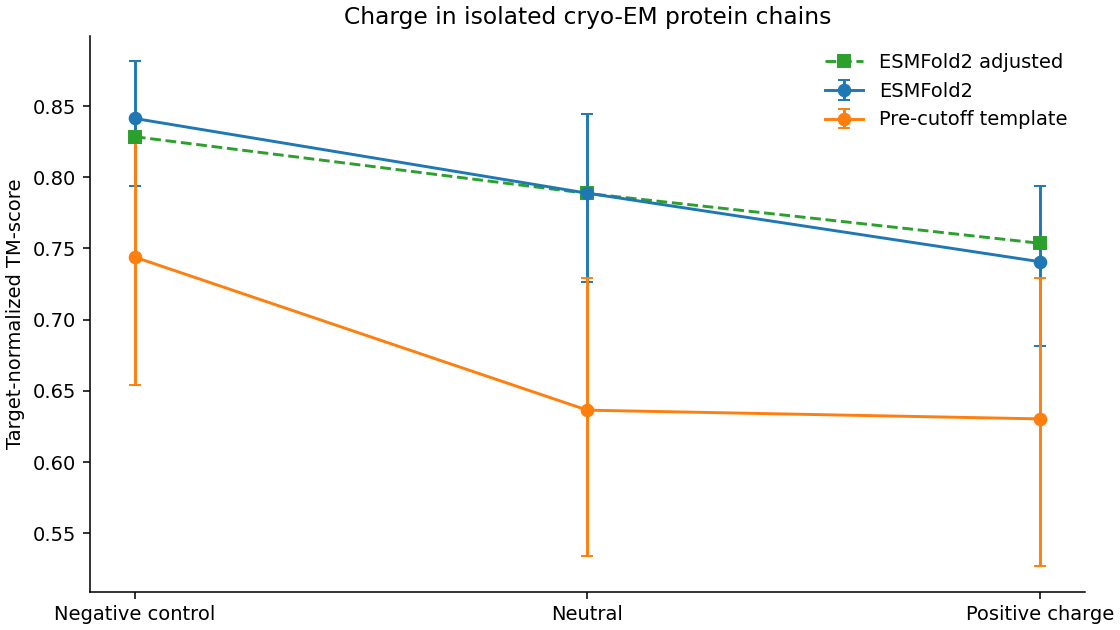

In [10]:
controls=['sequence_length','normalized_sequence_entropy','distant_repeat4_coverage','max_residue_fraction','cysteine_fraction','gly_pro_fraction','hydrophobic_fraction','chain_multiplicity','template_sequence_identity','template_query_coverage','resolution_angstrom','target_resolved_ca_fraction']
def standardized_matrix(frame,columns):
    matrix=frame[columns].to_numpy(float);mean=matrix.mean(axis=0);sd=matrix.std(axis=0);sd[sd==0]=1
    return (matrix-mean)/sd
def hc3_fit(x,y):
    inverse=np.linalg.pinv(x.T@x);beta=inverse@x.T@y;residual=y-x@beta
    leverage=np.einsum('ij,jk,ik->i',x,inverse,x);weighted=(residual/np.maximum(1-leverage,1e-8))**2
    covariance=inverse@(x.T@(x*weighted[:,None]))@inverse
    return beta,np.sqrt(np.maximum(0,np.diag(covariance)))
covariates=standardized_matrix(measurements,controls)
charge=standardized_matrix(measurements,['net_charge_proxy'])
y=measurements.tm_model.to_numpy(float)
continuous_x=np.column_stack([np.ones(len(y)),charge,covariates]);beta,se=hc3_fit(continuous_x,y)
dummies=np.column_stack([measurements.charge_level.eq(level).astype(float) for level in LEVELS[1:]])
category_x=np.column_stack([np.ones(len(y)),dummies,covariates]);level_beta,level_se=hc3_fit(category_x,y)
adjusted_means=[float(level_beta[0]),float(level_beta[0]+level_beta[1]),float(level_beta[0]+level_beta[2])]
model_matrix=measurements.pivot(index='charge_set_id',columns='charge_level',values='tm_model').reindex(columns=LEVELS).to_numpy()
reference_matrix=measurements.pivot(index='charge_set_id',columns='charge_level',values='tm_reference').reindex(columns=LEVELS).to_numpy()
if not np.isfinite(model_matrix).all() or not np.isfinite(reference_matrix).all():raise ValueError('Incomplete matched-set outcomes')
rng=np.random.default_rng(20260716);draws=rng.integers(0,len(model_matrix),size=(10000,len(model_matrix)))
model_draws=model_matrix[draws].mean(axis=1);reference_draws=reference_matrix[draws].mean(axis=1)
contrast=float(model_matrix[:,2].mean()-model_matrix[:,0].mean());contrast_draws=model_draws[:,2]-model_draws[:,0]
interval=np.quantile(contrast_draws,[.025,.975]);reference_decline=float(reference_matrix[:,0].mean()-reference_matrix[:,2].mean())
model_decline=-contrast;paired_difference=(model_draws[:,0]-model_draws[:,2])-(reference_draws[:,0]-reference_draws[:,2])
curve_rows=[]
for label,matrix,bootstrap in [('ESMFold2',model_matrix,model_draws),('Pre-cutoff template',reference_matrix,reference_draws)]:
    for j,level in enumerate(LEVELS):
        lo,hi=np.quantile(bootstrap[:,j],[.025,.975]);curve_rows.append({'model':label,'level':level,'n':len(matrix),'mean':float(matrix[:,j].mean()),'lo':float(lo),'hi':float(hi)})
curves=pd.DataFrame(curve_rows)
control_summary={'standardized_charge_coefficient':float(beta[1]),'hc3_se':float(se[1]),'normal_ci95':[float(beta[1]-1.96*se[1]),float(beta[1]+1.96*se[1])],'adjusted_level_means':dict(zip(LEVELS,adjusted_means)),'model_degradation':model_decline,'reference_degradation':reference_decline,'model_minus_reference_degradation':model_decline-reference_decline,'paired_ci95':np.quantile(paired_difference,[.025,.975]).tolist()}
display(curves);display(control_summary)
display(measurements.groupby('charge_level').agg(n=('candidate_id','size'),charge_median=('net_charge_proxy','median'),length_mean=('sequence_length','mean'),resolution_mean=('resolution_angstrom','mean'),template_identity_mean=('template_sequence_identity','mean'),resolved_fraction_mean=('target_resolved_ca_fraction','mean'),tm_below_half=('tm_model',lambda values:float((values<.5).mean()))))
fig,ax=plt.subplots(figsize=(8,4.5),layout='constrained')
for label,part in curves.groupby('model',sort=False):
    ax.errorbar(range(3),part['mean'],yerr=[part['mean']-part.lo,part.hi-part['mean']],marker='o',capsize=3,label=label)
ax.plot(range(3),adjusted_means,'s--',label='ESMFold2 adjusted')
ax.set(xticks=range(3),xticklabels=['Negative control','Neutral','Positive charge'],ylabel='Target-normalized TM-score',title='Charge in isolated cryo-EM protein chains');ax.legend(frameon=False);ax.spines[['top','right']].set_visible(False)
buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=140);plt.close(fig);display(Image(data=buffer.getvalue()))


## 6. What the agent decided, and why

Apply the−0.09 effect threshold, matched-set interval, monotone adjusted means and negative adjusted charge coefficient to the calculated results. Characterize the effect using the paired template contrast.


In [11]:
supported=bool(contrast<=-.09 and interval[1]<0 and np.all(np.diff(adjusted_means)<0) and beta[1]<0)
if supported:
    decision='Positive net charge meets the effect-size, uncertainty and adjusted-direction criteria for an accuracy decline in this cohort.'
else:decision='The current calculations do not jointly meet the effect-size, uncertainty and adjusted-direction criteria.'
print(decision)
print(f'Positive-minus-negative TM-score={contrast:.6f};95% matched-set interval=[{interval[0]:.6f},{interval[1]:.6f}].')
print('Reference comparison:','shared difficulty under the template reference' if reference_decline>=model_decline and model_decline>0 else 'inspect the model/reference contrasts above')
curves.to_csv(ROOT/'curves.csv',index=False);features.to_csv(ROOT/'axis_levels.csv',index=False)
(ROOT/'controls.json').write_text(json.dumps(control_summary,indent=2))
receipt={'analysis_id':'esmfold2-codex-r2/test-01','completed':True,'host':socket.gethostname(),'targets':len(features),'matched_sets':len(counts),'new_inference_executed':bool(pending),'verified_predictions_reused':len(features)-len(pending),'search_sources':search_sources,'controls_from_public_inputs':True,'model_source_revisions':{'fold':'1ebf0e3481a5184eb6171d40615c79e384b48796','esmc':'45b0fa5d7fb06faefbd5e3b89bdcef35d564e79a'},'checkpoint':checkpoint_signature,'settings':settings,'usalign_commit':USALIGN_COMMIT,'input_manifest_sha256':sha256_file(manifest_path),'source_files':structure_sources,'decision':decision,'bootstrap_replicates':10000,'bootstrap_seed':20260716}
(ROOT/'CALCULATION_RECEIPT.json').write_text(json.dumps(receipt,indent=2))


Positive net charge meets the effect-size, uncertainty and adjusted-direction criteria for an accuracy decline in this cohort.
Positive-minus-negative TM-score=-0.100594;95% matched-set interval=[-0.179071,-0.021679].
Reference comparison: shared difficulty under the template reference


345738